## PDE discovery: Nonlinear Schrodinger Equation.

### Import needed libraries

In [ ]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# From the repo
from data_generation import Schrodinger
from estimators import BestSubset, CoCoLasso, Lasso, LohWainwright, WSINDy
from experiments import NLS_FULL, NLS_LAMBDAS, NLS_WSINDY_PDE, NLS_WSINDY_PDE_RADIUS
from pilot import PINN
from weak_form import SplitWeakForm, WeakForm

Generate true PDE and data.
* True PDE: the nonlinear Schrödinger equation $i\psi_t + a\psi_{xx} + b|\psi|^2\psi = 0$ with $a = 0.5$, $b = 1$, on $(x, t) \in [-5, 5] \times [0, \pi]$, and $\psi(x, 0) = 2\,\mathrm{sech}(x)$. Writing $\psi = u - iv$ gives two equations with three true terms each:
$$u_t = 0.5\,v_{xx} + u^2 v + v^3, \qquad v_t = -0.5\,u_{xx} - u^3 - u v^2.$$

In [2]:
pde = Schrodinger(a=0.5, b=1.0)

# (u_*, v_*) on a fine grid of the domain, shape (2, 256, 251): u_star[0] = u_*, u_star[1] = v_*
x = np.linspace(*pde.domain[0], 256)
t = np.linspace(*pde.domain[1], 251)
X, T = np.meshgrid(x, t, indexing="ij")
u_star = pde.solution(X, T)

* Data:
    * $n = 1000$, 
    * $(z_i, U_i = u_*(z_i) + \epsilon_{0i}, V_i = v_*(z_i) + \epsilon_{1i})$, $\epsilon_{ci} \overset{\text{i.i.d.}}{\sim} N(0, \sigma_c^2)$, $\sigma_c = \rho \times \text{RMS}(u_{*c})$ for $c = 0,1$, $\rho = 0.1$

In [3]:
n = 1000
rho = 0.1
seed = 0

# z_i uniform on the domain; U_i = u_*(z_i) + eps_0i, V_i = v_*(z_i) + eps_1i, sd(eps_c) = rho * RMS over a fixed fine grid
data = pde.random(n, rho, seed)
print("z_i: data.points, two arrays of shape", data.points[0].shape, "(x_i and t_i)")
print("(U_i, V_i): data.U, shape", data.U.shape, "with data.U[0] = U_i and data.U[1] = V_i")
print("RMS(u_*), RMS(v_*):", pde.rms.round(3), "-> sigma_0, sigma_1 = rho * RMS:", data.sigma.round(3))

z_i: data.points, two arrays of shape (1000,) (x_i and t_i)
(U_i, V_i): data.U, shape (2, 1000) with data.U[0] = U_i and data.U[1] = V_i
RMS(u_*), RMS(v_*): [0.632 0.632] -> sigma_0, sigma_1 = rho * RMS: [0.063 0.063]


* Plotting 

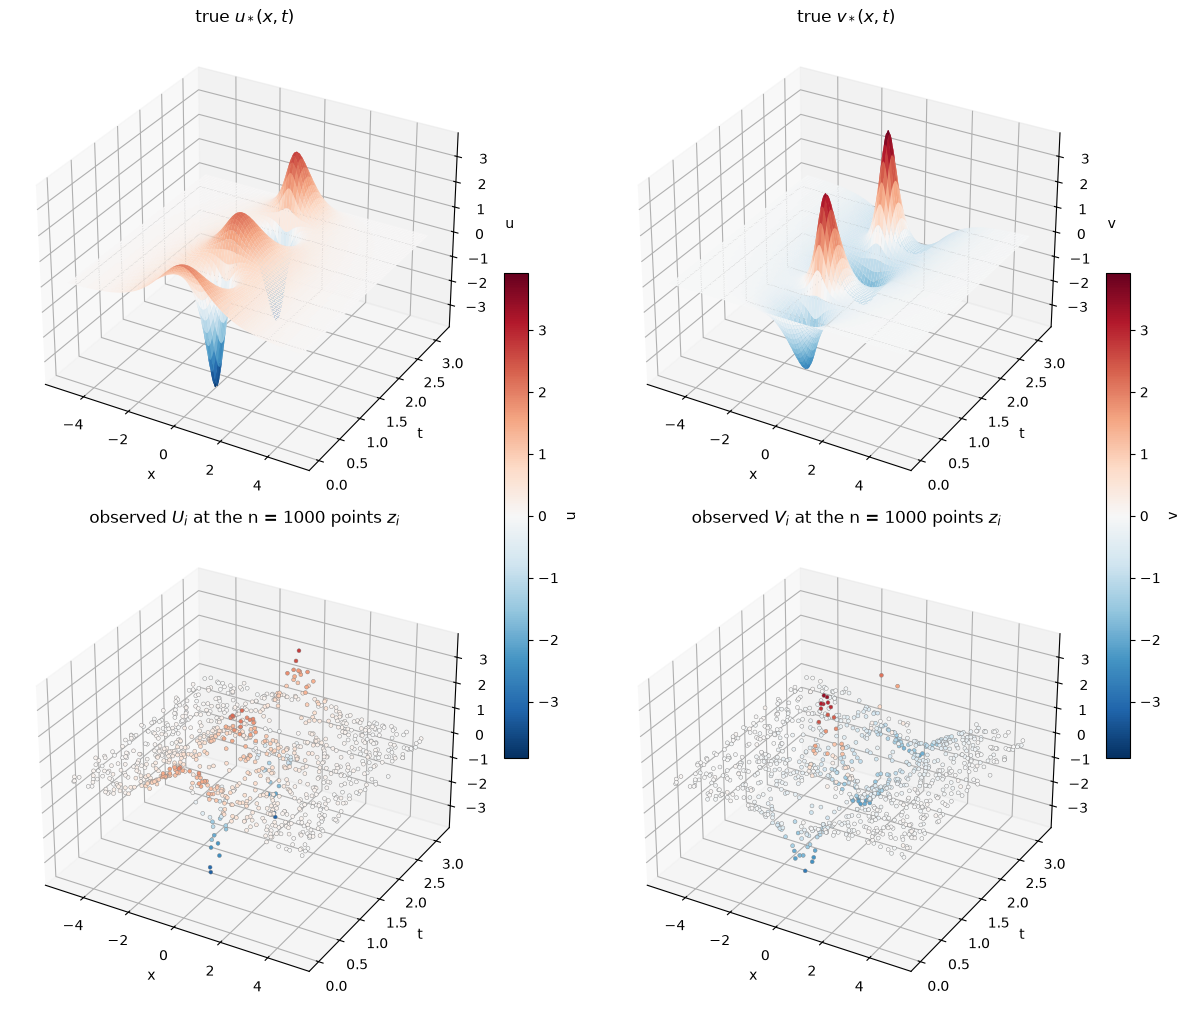

In [4]:
# Top: the true u_*, v_* as surfaces over (x, t). Bottom: the observations U_i, V_i as points above their z_i.
# Both rows of a column share the color scale and the vertical axis
fig, axes = plt.subplots(2, 2, figsize=(12, 10), subplot_kw={"projection": "3d"}, constrained_layout=True)
x_obs, t_obs = data.points
for c, (name, obs) in enumerate((("u", "U"), ("v", "V"))):
    lim = max(np.abs(u_star[c]).max(), np.abs(data.U[c]).max())
    surface = axes[0, c].plot_surface(X, T, u_star[c], cmap="RdBu_r", vmin=-lim, vmax=lim, rcount=100, ccount=100, linewidth=0)
    # Gray edges keep the points near 0, which are white, visible
    axes[1, c].scatter(x_obs, t_obs, data.U[c], c=data.U[c], s=8, cmap="RdBu_r", vmin=-lim, vmax=lim,
                       depthshade=False, edgecolors="0.5", linewidths=0.3)
    axes[0, c].set_title(f"true ${name}_*(x, t)$")
    axes[1, c].set_title(f"observed ${obs}_i$ at the n = {n} points $z_i$")
    fig.colorbar(surface, ax=axes[:, c], shrink=0.5, label=name)
    for ax in axes[:, c]:
        ax.set(xlabel="x", ylabel="t", zlabel=name, zlim=(-lim, lim))
plt.show()

### Determining the method.
* U method: u-hat or U_i
* debiased: true or false
* EIV: None or Loh-Wainwright or CocoLasso
* Support selection: MSTLS or LASSO or Best-subset
* Instances to compare: 
    * WSINDy: U_i & not debiased & None & MSTLS, 
    * Lasso: U_i & not debiased & None & LASSO
    * Loh-Wainwright: U_i & not debiased & Low-Wainwright & LASSO
    * CocoLASSO: U_i & not debiased & CocoLASSO & LASSO
    * Best-subset WSINDy: U_i & not debiased & None & Best-subset
    * plug-in WSINDy: u-hat & not debiased & None & MSTLS
    * plug-in best subset WSINDy: u-hat & not debiased & None & WSINDy
    * debiased WSINDy: u-hat & debiased & None & MSTLS
    * debiased best subset WSINDy: u-hat & debiased & None & Best-subset

In [5]:
# The axes of the method, as in the markdown above. Nothing is fit here: the instances are only labels, and the
# estimators are attached to them in the next section
choice_of_u = ["U_i", "u-hat (all n)", "u-hat (split)"]  # what X_n, Y_n are built from; u-hat is always the PINN
choice_of_debias = [False, True]                         # first-order correction of u-hat on the half it did not see
choice_of_eiv = ["None", "Loh-Wainwright", "CoCoLasso"]   # correction of the Gram matrix for the noise in U_i
choice_of_support = ["MSTLS", "LASSO", "Best-subset"]

# Each instance: (u, debiased, EIV, support selection)
instances = {
    "WSINDy":                      ("U_i", False, "None", "MSTLS"),
    "Lasso":                       ("U_i", False, "None", "LASSO"),
    "Loh-Wainwright":              ("U_i", False, "Loh-Wainwright", "LASSO"),
    "CoCoLasso":                   ("U_i", False, "CoCoLasso", "LASSO"),
    "Best-subset WSINDy":          ("U_i", False, "None", "Best-subset"),
    "plug-in WSINDy":              ("u-hat (all n)", False, "None", "MSTLS"),
    "plug-in best subset WSINDy":  ("u-hat (all n)", False, "None", "Best-subset"),
    "debiased WSINDy":             ("u-hat (split)", True, "None", "MSTLS"),
    "debiased best subset WSINDy": ("u-hat (split)", True, "None", "Best-subset"),
}

# Rule out the combinations that do not exist
for name, (u, debiased, eiv, support) in instances.items():
    assert u in choice_of_u and debiased in choice_of_debias and eiv in choice_of_eiv and support in choice_of_support, name
    # The correction is computed on the half that u-hat did not see, so it needs the split u-hat
    assert not debiased or u == "u-hat (split)", name
    # LW and CoCoLasso are lasso estimators corrected for the noise in U_i; with u-hat, Sigma_W is 0 on the grid
    assert eiv == "None" or (u == "U_i" and support == "LASSO"), name

pd.DataFrame.from_dict(instances, orient="index", columns=["u", "debiased", "EIV", "support selection"])

,u,debiased,EIV,support selection
WSINDy,U_i,False,None,MSTLS
Lasso,U_i,False,None,LASSO
Loh-Wainwright,U_i,False,Loh-Wainwright,LASSO
CoCoLasso,U_i,False,CoCoLasso,LASSO
Best-subset WSINDy,U_i,False,None,Best-subset
plug-in WSINDy,u-hat (all n),False,None,MSTLS
plug-in best subset WSINDy,u-hat (all n),False,None,Best-subset
debiased WSINDy,u-hat (split),True,None,MSTLS
debiased best subset WSINDy,u-hat (split),True,None,Best-subset


### Training u-hat using PINN

* Trained using neural network: $(\hat u, \hat v)$ is a fully connected network from $z = (x, t)$ to the two components, fit to the observations by least squares with Sobolev norm penalty,
$$(\hat u, \hat v) = \arg\min_{(u, v)} \frac{1}{n}\sum_{i=1}^n \big[(U_i - u(z_i))^2 + (V_i - v(z_i))^2\big] + \kappa \big(\|u\|_{W^{2,2}}^2 + \|v\|_{W^{2,2}}^2\big),$$
$$\|u\|_{W^{2,2}}^2 = \frac{1}{|\Omega|}\int_\Omega \big(u^2 + u_x^2 + u_t^2 + u_{xx}^2 + u_{xt}^2 + u_{tt}^2\big)\,dz,$$
* 3-layer neural network, width = (64, 64, 64): three hidden layers of 64 units with $\tanh$ activation. Inside the network, the input $(x, t)$ is scaled to $[-1, 1]^2$, and the output by the mean and sd of $(U_i, V_i)$.
* Adam with $\texttt{lr} = 10^{-3}$ on the full batch.
* Set $\kappa = 0$.
* Epoch is determined by early stopping, with 20% validation dataset: 20% of the observations are held out at random, the network is trained on the other 80% for up to 5000 epochs, and the epoch with the least validation error is chosen. A new network, from the same initial weights, is then trained on all the observations for that many epochs.
* Two kinds of u-hat, as the instances need:
    * u-hat (all n): fit to all $n = 1000$ observations.
    * u-hat (split): sample splitting. The observations are split in half: $(\hat u, \hat v)$ is fit to one half (500 observations), and the other half, which $(\hat u, \hat v)$ has not seen, is used only for the debiasing term of the debiased instances.

In [6]:
# The pilot of every u-hat instance, with the settings of NLS_PINN in experiments.py
pinn = PINN(hidden=(64, 64, 64), activation="tanh", epochs=5000, lr=1e-3, validation=0.2, refit=True)

# u-hat (all n): fit to all n observations, with the seed main.run gives it
uhat = pinn(data, seed=(seed, 1))

# u-hat (split): sample splitting. One half of the observations fits u-hat, and the other half is kept for the
# debiasing term, which needs observations that u-hat has not seen. data.split() gives (second half, first half)
fit_half, debias_half = data.split()
uhat_split = pinn(fit_half, seed=(seed, 1, 0))

# The chosen number of epochs, and the RMSE of (u-hat, v-hat) against (u_*, v_*) on the grid
rmse = lambda u: np.sqrt(np.mean((u(X, T) - u_star)**2, axis=(1, 2))).round(3)
print(f"u-hat (all n): {uhat.epochs:4d} epochs on {data.U.shape[-1]} observations, RMSE (u, v) = {rmse(uhat)}")
print(f"u-hat (split): {uhat_split.epochs:4d} epochs on {fit_half.U.shape[-1]} observations, RMSE (u, v) = {rmse(uhat_split)}")
print("noise sd (sigma_0, sigma_1) =", data.sigma.round(3))

u-hat (all n): 1568 epochs on 1000 observations, RMSE (u, v) = [0.044 0.048]
u-hat (split):  962 epochs on 500 observations, RMSE (u, v) = [0.055 0.091]
noise sd (sigma_0, sigma_1) = [0.063 0.063]


goodness-of-fit for u-hat

In [7]:
# Print L^2(\Omega) error between u_* and u-hat
# ||u-hat - u_*||_{L^2(Omega)} = (int_Omega (u-hat - u_*)^2 dz)^(1/2) per component, by the trapezoidal rule on the grid
l2 = lambda g: np.sqrt(np.trapezoid(np.trapezoid(g**2, t, axis=-1), x, axis=-1))
print("||u_*||, ||v_*|| =", l2(u_star).round(3))
for label, u in (("u-hat (all n)", uhat), ("u-hat (half n)", uhat_split)):
    error = l2(u(X, T) - u_star)
    print(f"{label:14s}: ||u-hat - u_*||, ||v-hat - v_*|| = {error.round(3)}, relative error (u, v) = {(error/l2(u_star)).round(3)}")

||u_*||, ||v_*|| = [3.545 3.545]
u-hat (all n) : ||u-hat - u_*||, ||v-hat - v_*|| = [0.244 0.269], relative error (u, v) = [0.069 0.076]
u-hat (half n): ||u-hat - u_*||, ||v-hat - v_*|| = [0.31  0.508], relative error (u, v) = [0.087 0.143]


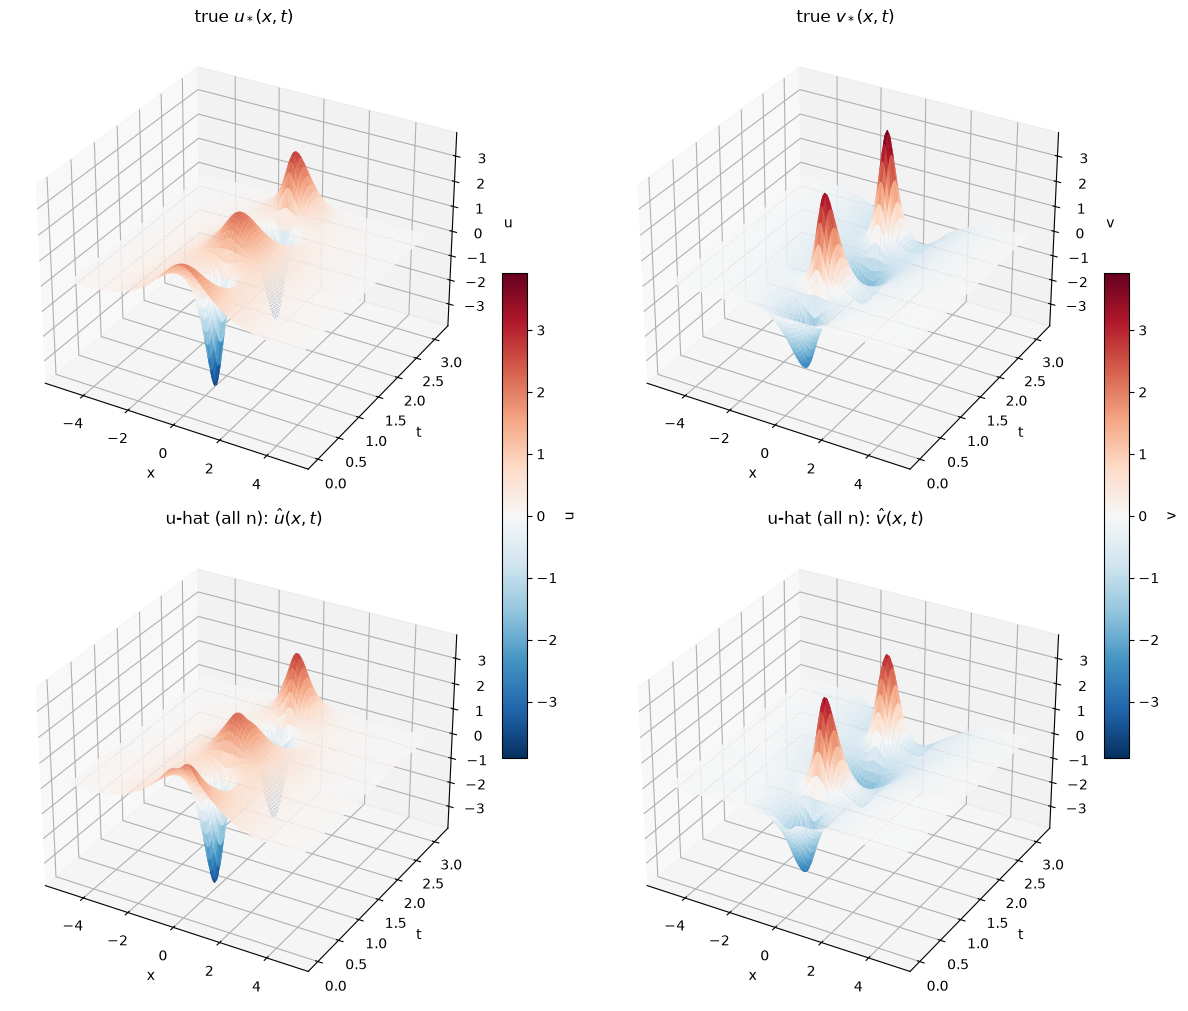

In [8]:
# Top: the true u_*, v_*. Bottom: u-hat (all n), on the same color scale and vertical axis
fig, axes = plt.subplots(2, 2, figsize=(12, 10), subplot_kw={"projection": "3d"}, constrained_layout=True)
value = uhat(X, T)
for c, name in enumerate(("u", "v")):
    lim = max(np.abs(u_star[c]).max(), np.abs(data.U[c]).max())
    surface = axes[0, c].plot_surface(X, T, u_star[c], cmap="RdBu_r", vmin=-lim, vmax=lim, rcount=100, ccount=100, linewidth=0)
    axes[1, c].plot_surface(X, T, value[c], cmap="RdBu_r", vmin=-lim, vmax=lim, rcount=100, ccount=100, linewidth=0)
    axes[0, c].set_title(f"true ${name}_*(x, t)$")
    axes[1, c].set_title(f"u-hat (all n): $\\hat {name}(x, t)$")
    fig.colorbar(surface, ax=axes[:, c], shrink=0.5, label=name)
    for ax in axes[:, c]:
        ax.set(xlabel="x", ylabel="t", zlabel=name, zlim=(-lim, lim))
plt.show()

### Weak form generation

* Weak form: multiply the PDE by test functions $\phi_k$, $k = 1, \dots, K$, which vanish with their derivatives on the boundary of $\Omega$, and integrate by parts so that every derivative falls on $\phi_k$. Both equations share the $P$ candidate terms $\partial^{\alpha_l} f_l(u, v)$, so the PDE becomes one linear system
$$Y = X\beta, \qquad X \in \mathbb{R}^{K \times P}, \quad Y \in \mathbb{R}^{K \times 2}, \quad \beta \in \mathbb{R}^{P \times 2},$$
$$X_{kl}(u, v) = \int_\Omega (-1)^{|\alpha_l|}\,\partial^{\alpha_l}\phi_k(z)\, f_l(u(z), v(z))\,dz, \qquad (Y_{k1}, Y_{k2})(u, v) = -\int_\Omega \partial_t\phi_k(z)\, \big(u(z), v(z)\big)\,dz,$$
whose two columns are the equations for $u_t$ and $v_t$. At the truth, $Y(u_*, v_*) = X(u_*, v_*)\,\beta_*$, with three nonzero entries in each column of $\beta_*$.
* Dictionary: the constant and $\partial_x^s(u^p v^q)$ for $s = 0, \dots, 6$ and $p + q = 1, \dots, 6$, so $P = 1 + 7 \times 27 = 190$.
* Test functions: those of the Schrödinger example of Messenger & Bortz (2021),
$$\phi_k(x, t) = \Big(1 - \big(\tfrac{x - x_k}{R_x}\big)^2\Big)_+^{11}\Big(1 - \big(\tfrac{t - t_k}{R_t}\big)^2\Big)_+^{10},$$
with $R_x = 0.742$, $R_t = 0.314$, and $44 \times 41$ centers, so $K = 1804$.
* The integrals, for each input of the instances, with $\widehat u = (\hat u, \hat v)$:
    * $U_i$: $X_n(U)$ and $Y_n(U)$, Monte Carlo over the $n$ observations,
    $$[X_n(U)]_{kl} = \frac{|\Omega|}{n}\sum_{i=1}^n (-1)^{|\alpha_l|}\partial^{\alpha_l}\phi_k(z_i)\, f_l(U_i, V_i), \qquad [Y_n(U)]_{k\cdot} = -\frac{|\Omega|}{n}\sum_{i=1}^n \partial_t\phi_k(z_i)\,(U_i, V_i).$$
    * u-hat (all n): $X_n(\widehat u)$ and $Y_n(\widehat u)$, with $\widehat u$ in place of $(u, v)$, summed by the rectangle rule on the $256 \times 251$ grid (plug-in).
    * u-hat (split), debiased: $X^{\mathrm{db}}_n(\widehat u)$ and $Y^{\mathrm{db}}_n(\widehat u)$. With $\widehat u$ fit to one half, $X_n(\widehat u)$ and $Y_n(\widehat u)$ plus the first-order correction on the other half $H$ (500 observations), which $\widehat u$ has not seen:
    $$[X^{\mathrm{db}}_n(\widehat u)]_{kl} = [X_n(\widehat u)]_{kl} + \frac{|\Omega|}{|H|}\sum_{i \in H} (-1)^{|\alpha_l|}\partial^{\alpha_l}\phi_k(z_i)\, \nabla f_l(\widehat u(z_i)) \cdot \big(U_i - \hat u(z_i),\, V_i - \hat v(z_i)\big),$$
    $$[Y^{\mathrm{db}}_n(\widehat u)]_{k\cdot} = [Y_n(\widehat u)]_{k\cdot} - \frac{|\Omega|}{|H|}\sum_{i \in H} \partial_t\phi_k(z_i)\, \big(U_i - \hat u(z_i),\, V_i - \hat v(z_i)\big).$$
    
    The corrections are the Monte Carlo estimates on $H$ of the Gateaux derivatives at $\widehat u$ in the direction $U - \widehat u$, and $Y_H(\cdot)$ below is the Monte Carlo sum on $H$:
    $$X^{\mathrm{db}}_n(\widehat u) = X_n(\widehat u) + \widehat{\partial_{U - \widehat u} X}(\widehat u), \qquad Y^{\mathrm{db}}_n(\widehat u) = Y_n(\widehat u) + \widehat{\partial_{U - \widehat u} Y}(\widehat u) = Y_H(U) + \big[\,Y_n(\widehat u) - Y_H(\widehat u)\,\big].$$
* Check, possible only in simulation: the distance of each $(X, Y)$ from $(X(u_*, v_*), Y(u_*, v_*))$ on the same grid.

In [9]:
# The dictionary (one Equation per equation of the PDE, each with its own candidate terms) and the test functions, as
# in experiments.py. Nothing below assumes two equations, two components or one space dimension
dictionary, phi = NLS_FULL, NLS_WSINDY_PDE
grid_shape = (256, 251)  # where u-hat is evaluated: the grid of Messenger & Bortz (2021)

# One weak form per kind of input in the instances, keyed by (u, debiased); wf.system(equation) gives its (X, Y)
weak_forms = {
    ("U_i", False): WeakForm(data, phi),
    ("u-hat (all n)", False): WeakForm(data, phi, uhat, "grid", grid_shape),
    ("u-hat (split)", True): SplitWeakForm(data, phi, uhat_split, debias_half, "grid", grid_shape, debias=True),
}
assert all((u, debiased) in weak_forms for u, debiased, _, _ in instances.values())

# beta_* of each equation, on the columns of its dictionary
beta_star = [pde.coefficients(equation) for equation in dictionary]
print(f"K = {np.prod([len(c) for c in phi.centers])} test functions; P = {[len(eq.rhs) for eq in dictionary]} terms per equation")

# Check, possible only in simulation: the distance of each (X, Y) from that of u_* on the same grid, relative to the
# latter, over all the columns of X and over the true terms of the equation only
truth = WeakForm(data, phi, pde.solution, "grid", grid_shape)
rel = lambda A, B: np.linalg.norm(A - B)/np.linalg.norm(B)
table = []
for (u, debiased), wf in weak_forms.items():
    row = [u + (", debiased" if debiased else "")]
    for equation, star in zip(dictionary, beta_star):
        (X, Y), (Xt, Yt) = wf.system(equation), truth.system(equation)
        row += [rel(X, Xt), rel(X[:, star != 0], Xt[:, star != 0]), rel(Y, Yt)]
    table.append(row)
columns = [f"{m}, eq {q}" for q in range(len(dictionary)) for m in ("X all terms", "X true terms", "Y")]
pd.DataFrame(table, columns=["input", *columns]).set_index("input").round(3)

K = 1804 test functions; P = [190, 190] terms per equation


,"X all terms, eq 0","X true terms, eq 0","Y, eq 0","X all terms, eq 1","X true terms, eq 1","Y, eq 1"
input,,,,,,
U_i,2.265,3.404,1.356,2.265,3.014,1.329
u-hat (all n),0.622,0.260,0.101,0.622,0.198,0.091
"u-hat (split), debiased",1.053,0.631,0.206,1.053,0.478,0.278


### LASSO sanity check

Check whether the constructed $X_n(u)$ satisfies the irrepresentability condition (https://www.jmlr.org/papers/volume7/zhao06a/zhao06a.pdf). It involves $X$ and the signs of $\beta_*$ only, not $Y$.

* For one equation, let $S$ be its true terms (3) and $S^c$ the other $P - 3$, and $C = Z^\top Z/K$ the Gram matrix of the standardized columns $Z = XD^{-1}$, on which the lasso is solved. The strong irrepresentable condition of Zhao & Yu (2006) is
$$\eta = \big\Vert\, C_{S^cS}\, C_{SS}^{-1}\, \mathrm{sign}(\beta_{*,S}) \,\big\Vert_\infty < 1.$$
If $\eta < 1$, the lasso selects $S$ with the correct signs for some $\lambda$; if $\eta > 1$, it cannot.
* Its sign-free, stronger version (mutual incoherence, Wainwright 2009) is $\mu = \big\Vert C_{S^cS}\, C_{SS}^{-1}\big\Vert_\infty < 1$, the largest $\ell_1$ norm of a row.
* Computed for each equation, separately for the two kinds of input, each next to $X(u_*, v_*)$ on the grid for reference:
    * with $U_i$: $X_n(U)$, and $X^\top X/K - \widehat\Sigma_W$ in place of $X^\top X/K$, as LW and CoCoLasso use it;
    * with $\widehat u$: $X_n(\widehat u)$ with u-hat (all n), and $X^{\mathrm{db}}_n(\widehat u)$ with u-hat (split).

In [ ]:
# Irrepresentable condition (Zhao & Yu 2006) of each equation: eta = ||C_{S^c S} C_{SS}^{-1} sign(beta_*S)||_inf < 1, and its
# sign-free version mu = ||C_{S^c S} C_{SS}^{-1}||_inf < 1, with C the Gram matrix of the standardized columns


def irrepresentability(C, star):
    S = star != 0
    A = C[np.ix_(~S, S)] @ np.linalg.inv(C[np.ix_(S, S)])  # row j: false term j regressed on the true terms
    return np.abs(A @ np.sign(star[S])).max(), np.abs(A).sum(axis=1).max()


def gram(X, Sigma=0):
    # C = D^{-1} (X'X/K - Sigma) D^{-1}: the Gram matrix of the standardized columns, less Sigma_W for LW and CoCoLasso
    d = np.sqrt(np.mean(X**2, axis=0))
    return (X.T @ X/len(X) - Sigma)/np.outer(d, d)


def irrepresentability_table(grams):
    # grams: {label: function of the equation giving its C}; one row per label, (eta, mu) per equation
    table = [[label] + [m for equation, star in zip(dictionary, beta_star) for m in irrepresentability(C(equation), star)]
             for label, C in grams.items()]
    columns = [f"{m}, eq {q}" for q in range(len(dictionary)) for m in ("eta", "mu")]
    return pd.DataFrame(table, columns=["X", *columns]).set_index("X").round(2)


# With U_i
wf = weak_forms[("U_i", False)]
irrepresentability_table({
    "X(u_*, v_*), reference": lambda equation: gram(truth.system(equation)[0]),
    "X_n(U)": lambda equation: gram(wf.system(equation)[0]),
    "X_n(U), X'X/K - Sigma_W (LW, CoCoLasso)": lambda equation: gram(wf.system(equation)[0], wf.noise_covariance(equation)),
})

In [ ]:
# With u-hat
irrepresentability_table({
    "X(u_*, v_*), reference": lambda equation: gram(truth.system(equation)[0]),
    "X_n(u-hat), u-hat (all n)": lambda equation: gram(weak_forms[("u-hat (all n)", False)].system(equation)[0]),
    "X_n^db(u-hat), u-hat (split)": lambda equation: gram(weak_forms[("u-hat (split)", True)].system(equation)[0]),
})

### Estimation stage

Fit $\widehat \beta$ for each of the **9 instances**, one column (equation) at a time. Each instance applies one of the 5 estimators below to one of the 3 weak forms of the section above:

| | Instance | Weak form $(X, Y)$ | Estimator |
|---|---|---|---|
| 1 | WSINDy | $X_n(U)$, $Y_n(U)$ | MSTLS |
| 2 | Lasso | $X_n(U)$, $Y_n(U)$ | LASSO |
| 3 | Loh-Wainwright | $X_n(U)$, $Y_n(U)$ | Loh-Wainwright |
| 4 | CoCoLasso | $X_n(U)$, $Y_n(U)$ | CoCoLasso |
| 5 | Best-subset WSINDy | $X_n(U)$, $Y_n(U)$ | Best subset |
| 6 | plug-in WSINDy | $X_n(\widehat u)$, $Y_n(\widehat u)$ with u-hat (all n) | MSTLS |
| 7 | plug-in best subset WSINDy | $X_n(\widehat u)$, $Y_n(\widehat u)$ with u-hat (all n) | Best subset |
| 8 | debiased WSINDy | $X^{\mathrm{db}}_n(\widehat u)$, $Y^{\mathrm{db}}_n(\widehat u)$ with u-hat (split) | MSTLS |
| 9 | debiased best subset WSINDy | $X^{\mathrm{db}}_n(\widehat u)$, $Y^{\mathrm{db}}_n(\widehat u)$ with u-hat (split) | Best subset |

The 5 estimators, with $D = \mathrm{diag}(\Vert X_l\Vert_2/\sqrt K)$ the column scales:

| EIV, support selection | Estimator | Tuning |
|---|---|---|
| None, MSTLS | MSTLS of Messenger & Bortz (2021), without their rescaling | $\lambda$ by the MSTLS loss, over 50 values in $[10^{-4}, 1]$ |
| None, LASSO | $\arg\min_\beta \frac{1}{2K}\Vert Y - X\beta\Vert_2^2 + \lambda\Vert D\beta\Vert_1$ | $\lambda$ by the MSTLS loss, over 50 values on its path |
| Loh-Wainwright, LASSO | Loh & Wainwright (2012), eq. (2.7): $\arg\min_{\Vert D\beta\Vert_1 \le R} \frac12\beta^\top\big(X^\top X/K - \widehat\Sigma_W\big)\beta - \beta^\top X^\top Y/K + \lambda\Vert D\beta\Vert_1$ | $\lambda$ by the corrected 5-fold CV of Datta & Zou (2017), over 18 values in $[0.005, 1]$; $R = 0.79$, an oracle value from $\beta_*$ |
| CoCoLasso, LASSO | Datta & Zou (2017): the same with $X^\top X/K - \widehat\Sigma_W$ replaced by its nearest positive semidefinite matrix, and no radius | the same CV |
| None, Best-subset | Bertsimas, King & Mazumder (2016): $\arg\min_\beta \Vert Y - X\beta\Vert_2^2$ s.t. $\Vert\beta\Vert_0 \le k$, for $k = 1, \dots, 10$, by Gurobi | $k$ by the MSTLS loss |

* The MSTLS loss of $\beta$ is $\Vert X(\beta - \beta_{\mathrm{LS}})\Vert_2/\Vert X\beta_{\mathrm{LS}}\Vert_2 + \Vert\beta\Vert_0/P$, with $\beta_{\mathrm{LS}}$ the least squares on all $P$ columns.
* $\widehat\Sigma_W$ is the sample covariance of the noise in $X_n(U)$, so LW and CoCoLasso are used with $U_i$ only.

In [ ]:
# The estimator of each (EIV, support selection), with the settings of experiments.py
estimators = {
    ("None", "MSTLS"): WSINDy("mstls"),
    ("None", "LASSO"): Lasso("mb"),
    ("Loh-Wainwright", "LASSO"): LohWainwright(NLS_LAMBDAS, NLS_WSINDY_PDE_RADIUS[n], standardize=True),
    ("CoCoLasso", "LASSO"): CoCoLasso(NLS_LAMBDAS),
    ("None", "Best-subset"): BestSubset("mb"),
}
assert all((eiv, support) in estimators for _, _, eiv, support in instances.values())
print(f"{len(instances)} instances, each pairing one of the {len(weak_forms)} weak forms with one of the {len(estimators)} estimators")

# beta-hat of each instance, one array per equation: its estimator on the weak form of its input
beta_hat = {}
for name, (u, debiased, eiv, support) in instances.items():
    start = time.time()
    beta_hat[name] = [estimators[(eiv, support)].estimate(weak_forms[(u, debiased)], equation) for equation in dictionary]
    print(f"{name:28s} {time.time() - start:6.1f} s, nonzero coefficients per equation: {[int(np.sum(b != 0)) for b in beta_hat[name]]}")